# SafeRoute 3D — Faz 3: Mekânsal Kümeleme Deneyleri

Bu defter **sunum ve doğrulama modunda** çalışır: hiçbir model yeniden eğitilmez. Tüm sayılar
`saferoute cluster` komutunun ürettiği deney kaydından (`experiments_registry.json`), kontrol noktasından
(`results_checkpoint.json`), `results.json`'dan ve olay düzeyi etiket dosyalarından (`labels/*.npz`) okunur
ve birbirleriyle çapraz doğrulanır.

| Algoritma | Öznitelik seti | Fit kapsamı |
|---|---|---|
| DBSCAN | A: haversine `[lat_rad, lon_rad]`, ağırlıklı benzersiz konum | tam veri |
| K-Means | B: EPSG:32618 `[x_m, y_m]`, ağırlıklı | tam veri |
| HDBSCAN | B: EPSG:32618, olay düzeyi | 100k olay örneklemi |

In [1]:
import hashlib, json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from saferoute import config
from saferoute.clustering.data import processed_dir
from saferoute.clustering.evaluation import cluster_stats
from saferoute.clustering.report import temporal_interpretation
from saferoute.clustering.settings import load_config

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
CFG = load_config()
P3 = processed_dir() / "phase3"
REP = config.REPORTS_DIR / "phase3"
R = json.loads((P3 / "results.json").read_text(encoding="utf-8"))
REG = json.loads((P3 / "experiments_registry.json").read_text(encoding="utf-8"))
REG = REG if isinstance(REG, list) else REG.get("records", REG)
REG = {r["experiment_id"]: r for r in (REG.values() if isinstance(REG, dict) else REG)}
CK = json.loads((P3 / "results_checkpoint.json").read_text(encoding="utf-8"))
fig = lambda name: display(Image(filename=str(REP / "figures" / name)))
print("Veri sürümü :", R["meta"]["dataset_version"])
print("İşlem sürümü:", R["meta"]["processing_version"])
print("Deney sayısı:", len(REG), pd.Series([r["status"] for r in REG.values()]).value_counts().to_dict())

Veri sürümü : raw:2fe1297c24f7|p2cfg:c7ffbfdc478d|p2:2.1.1
İşlem sürümü: phase3-code:3.0.0|phase3-config:977132f9821d
Deney sayısı: 115 {'success': 114, 'skipped_resource_limit': 1}


## 1. Kayıt, kontrol noktası ve yapılandırma tutarlılığı

In [2]:
assert CK["config_sha256"] == CFG["_sha256"] == R["meta"]["config_sha256"], "yapılandırma özeti uyuşmuyor"
assert CK["dataset_version"] == R["meta"]["dataset_version"]
print("Kontrol noktasında tamamlanan aşamalar:", CK["done"])
missing = [i for i, r in REG.items() if r["status"] == "success" and not Path(r["labels_path"]).exists()]
assert not missing, f"etiket dosyası eksik: {missing}"
bad = {i: r["status"] for i, r in REG.items() if r["status"] != "success"}
print("Başarılı olmayan deneyler (sahte sonuç üretilmedi):")
pd.DataFrame([{"experiment_id": i, "stage": REG[i]["stage"], "params": REG[i]["params"], "status": s,
               "error": REG[i].get("error")} for i, s in bad.items()])

Kontrol noktasında tamamlanan aşamalar: ['integrity', 'kdistance', 'equivalence', 'dbscan', 'kmeans', 'hdbscan', 'evaluate', 'select', 'review', 'temporal', 'sensitivity', 'profiles']
Başarılı olmayan deneyler (sahte sonuç üretilmedi):


,experiment_id,stage,params,status,error
0,dbscan-89570d3913,equivalence,"{'eps_m': 50, 'min_samples': 10}",skipped_resource_limit,"Tahmini komşu çifti 310,691,918 > sınır 300,00..."


In [3]:
# Aşama bazında deney dökümü
pd.DataFrame([{"stage": r["stage"], "algorithm": r["algorithm"], "status": r["status"]} for r in REG.values()]) \
  .value_counts().rename("deney").reset_index().sort_values(["stage", "algorithm"])

,stage,algorithm,status,deney
2,dbscan_grid,dbscan,success,20
0,equivalence,dbscan,success,34
7,equivalence,dbscan,skipped_resource_limit,1
4,hdbscan_grid,hdbscan,success,12
5,kmeans_grid,kmeans,success,5
6,sensitivity,dbscan,success,4
1,temporal,dbscan,success,26
3,temporal,kmeans,success,13


## 2. Veri ve matris bütünlüğü

In [4]:
integ = R["integrity"]
print({k: integ[k] for k in ("raw_rows", "eligible_events", "unique_locations", "weight_sum")})
pd.DataFrame([{"kontrol": k, "ok": v["ok"], "ayrıntı": v["detail"]} for k, v in integ["checks"].items()])

{'raw_rows': 2269187, 'eligible_events': 2020638, 'unique_locations': 349122, 'weight_sum': 2020638}


,kontrol,ok,ayrıntı
0,collision_id_unique,True,2269187
1,processed_rows_match_sidecar,True,"{'rows': 2269187, 'sidecar': 2269187}"
2,A_dbscan_haversine_rows_equal_eligible,True,2020638
3,A_dbscan_haversine_order_matches,True,None
4,B_kmeans_projected_rows_equal_eligible,True,2020638
5,B_kmeans_projected_order_matches,True,None
6,C_hdbscan_haversine_rows_equal_eligible,True,2020638
7,C_hdbscan_haversine_order_matches,True,None
8,D_spatiotemporal_experimental_rows_equal_eligible,True,2020638
9,D_spatiotemporal_experimental_order_matches,True,None


## 3. Ağırlıklı k-mesafe

,0 m payı,p10,p25,p50,p75,p90,p95
10,0.72,0.0,0.0,0.00,0.38,29.10,51.14
25,0.52,0.0,0.0,0.00,20.46,69.45,83.01
50,0.32,0.0,0.0,0.99,65.04,88.75,118.12
100,0.16,0.0,0.7,57.85,88.32,140.96,165.76


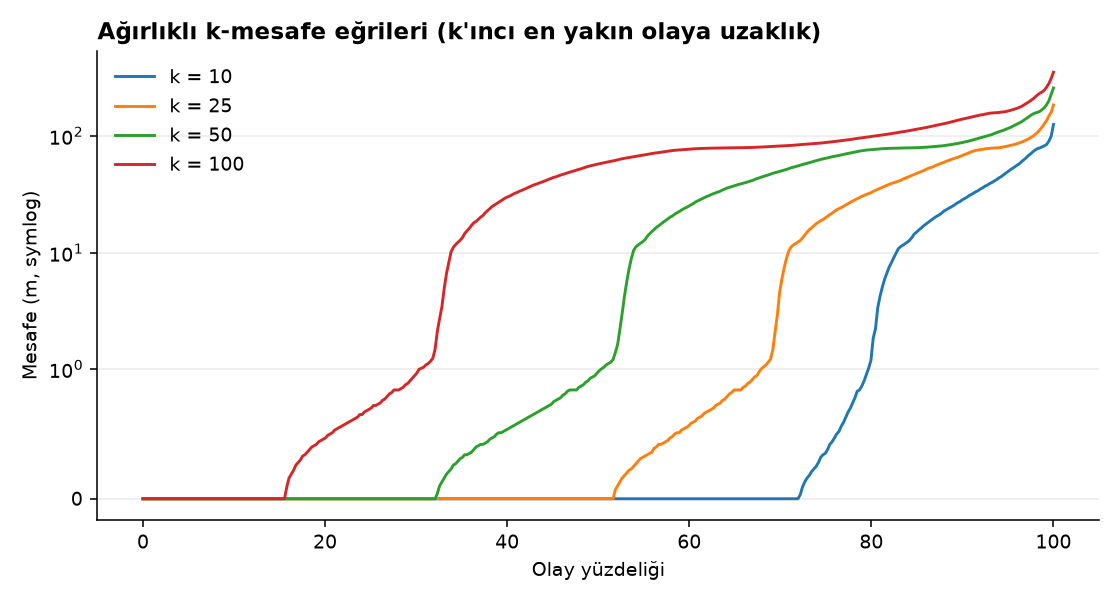

In [5]:
display(pd.DataFrame({k: {"0 m payı": v["zero_distance_share"], **{f"p{p}": q for p, q in v["percentiles_m"].items()}}
                      for k, v in R["kdistance"]["by_k"].items()}).T.round(2))
fig("k_distance.png")

## 4. Ağırlıklı DBSCAN ile kayıt düzeyi DBSCAN eşdeğerliği (gerçek veri)

Tam veri kayıt düzeyi denemesi komşu çifti sınırını aştığı için **çalıştırılmadı** (kaynak sınırı olarak kaydedildi).

,label,eps_m,min_samples,n_events,n_unique_locations,core_identical,noise_identical,ari_all_events,records_neighbor_pairs,weighted_neighbor_pairs
0,Midtown Manhattan (çok yoğun),50,10,44073,4798,True,True,1.000000,13096575,81890
1,Midtown Manhattan (çok yoğun),50,25,44073,4798,True,True,1.000000,13096575,81890
2,Midtown Manhattan (çok yoğun),100,10,44073,4798,True,True,1.000000,33922131,285756
3,Midtown Manhattan (çok yoğun),100,25,44073,4798,True,True,1.000000,33922131,285756
4,Downtown Brooklyn (yoğun tekrar),50,10,15969,1414,True,True,0.999995,6431439,14860
5,Downtown Brooklyn (yoğun tekrar),50,25,15969,1414,True,True,0.999256,6431439,14860
6,Downtown Brooklyn (yoğun tekrar),100,10,15969,1414,True,True,1.000000,9160813,46220
7,Downtown Brooklyn (yoğun tekrar),100,25,15969,1414,True,True,1.000000,9160813,46220
8,"Jamaica, Queens (orta yoğunluk)",50,10,21177,3683,True,True,0.999798,2702077,38285
9,"Jamaica, Queens (orta yoğunluk)",50,25,21177,3683,True,True,0.999369,2702077,38285


Tam veri kayıt düzeyi: {'experiment_id': 'dbscan-89570d3913', 'status': 'skipped_resource_limit', 'error': 'Tahmini komşu çifti 310,691,918 > sınır 300,000,000 (~2.3 GiB yalnızca indeks); koşu çalıştırılmadı.', 'n_events': 2020638}


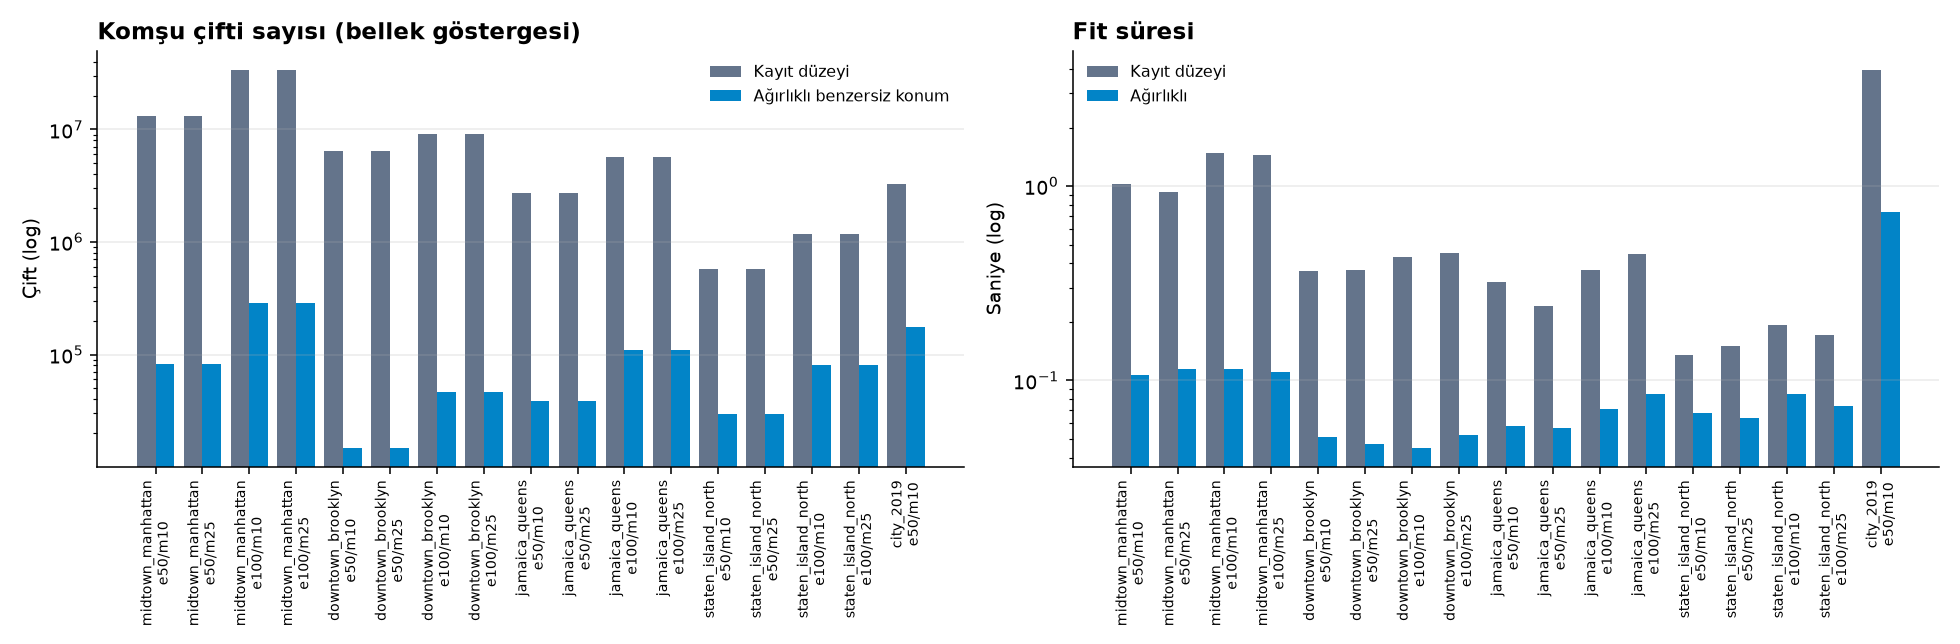

In [6]:
eq = pd.DataFrame(R["equivalence"]["scenarios"])
display(eq[["label", "eps_m", "min_samples", "n_events", "n_unique_locations", "core_identical", "noise_identical",
            "ari_all_events", "records_neighbor_pairs", "weighted_neighbor_pairs"]])
print("Tam veri kayıt düzeyi:", R["equivalence"]["full_data_records_attempt"])
fig("weighted_equivalence.png")

## 5. Izgara değerlendirmesi (ortak değerlendirme kümesi)

In [7]:
ev = pd.read_csv(REP / "tables" / "evaluation_all_configs.csv")
ev[["algorithm", "eps_m", "min_samples", "k", "min_cluster_size", "n_clusters_full", "noise_ratio_full",
    "n_clusters_eval", "noise_ratio_eval", "largest_cluster_share_eval", "silhouette_common", "davies_bouldin", "dbcv",
    "parameter_stability_ari", "runtime_s", "admissible"]].round(3)

,algorithm,eps_m,min_samples,k,min_cluster_size,n_clusters_full,noise_ratio_full,n_clusters_eval,noise_ratio_eval,largest_cluster_share_eval,silhouette_common,davies_bouldin,dbcv,parameter_stability_ari,runtime_s,admissible
0,dbscan,25.0,10.0,NaN,NaN,31615.0,0.093,23958,0.093,0.002,0.839,0.199,0.776,0.197,4.255,True
1,dbscan,25.0,25.0,NaN,NaN,19619.0,0.205,17714,0.206,0.001,0.911,0.127,0.718,0.357,4.079,True
2,dbscan,25.0,50.0,NaN,NaN,10462.0,0.376,10203,0.375,0.001,0.927,0.111,0.576,0.440,3.818,True
3,dbscan,25.0,100.0,NaN,NaN,4179.0,0.597,4171,0.596,0.001,0.945,0.090,0.394,0.480,3.870,True
4,dbscan,50.0,10.0,NaN,NaN,15038.0,0.034,11352,0.035,0.113,0.049,0.668,0.084,0.183,4.496,False
5,dbscan,50.0,25.0,NaN,NaN,10245.0,0.101,9263,0.101,0.087,0.202,0.624,0.255,0.284,4.952,False
6,dbscan,50.0,50.0,NaN,NaN,7134.0,0.213,6882,0.213,0.048,0.348,0.534,0.337,0.301,4.743,True
7,dbscan,50.0,100.0,NaN,NaN,4570.0,0.396,4505,0.396,0.012,0.517,0.406,0.352,0.290,4.766,True
8,dbscan,100.0,10.0,NaN,NaN,890.0,0.002,706,0.002,0.557,-0.731,1.185,-0.830,0.631,6.194,False
9,dbscan,100.0,25.0,NaN,NaN,911.0,0.010,819,0.010,0.511,-0.696,1.043,-0.758,0.661,5.816,False


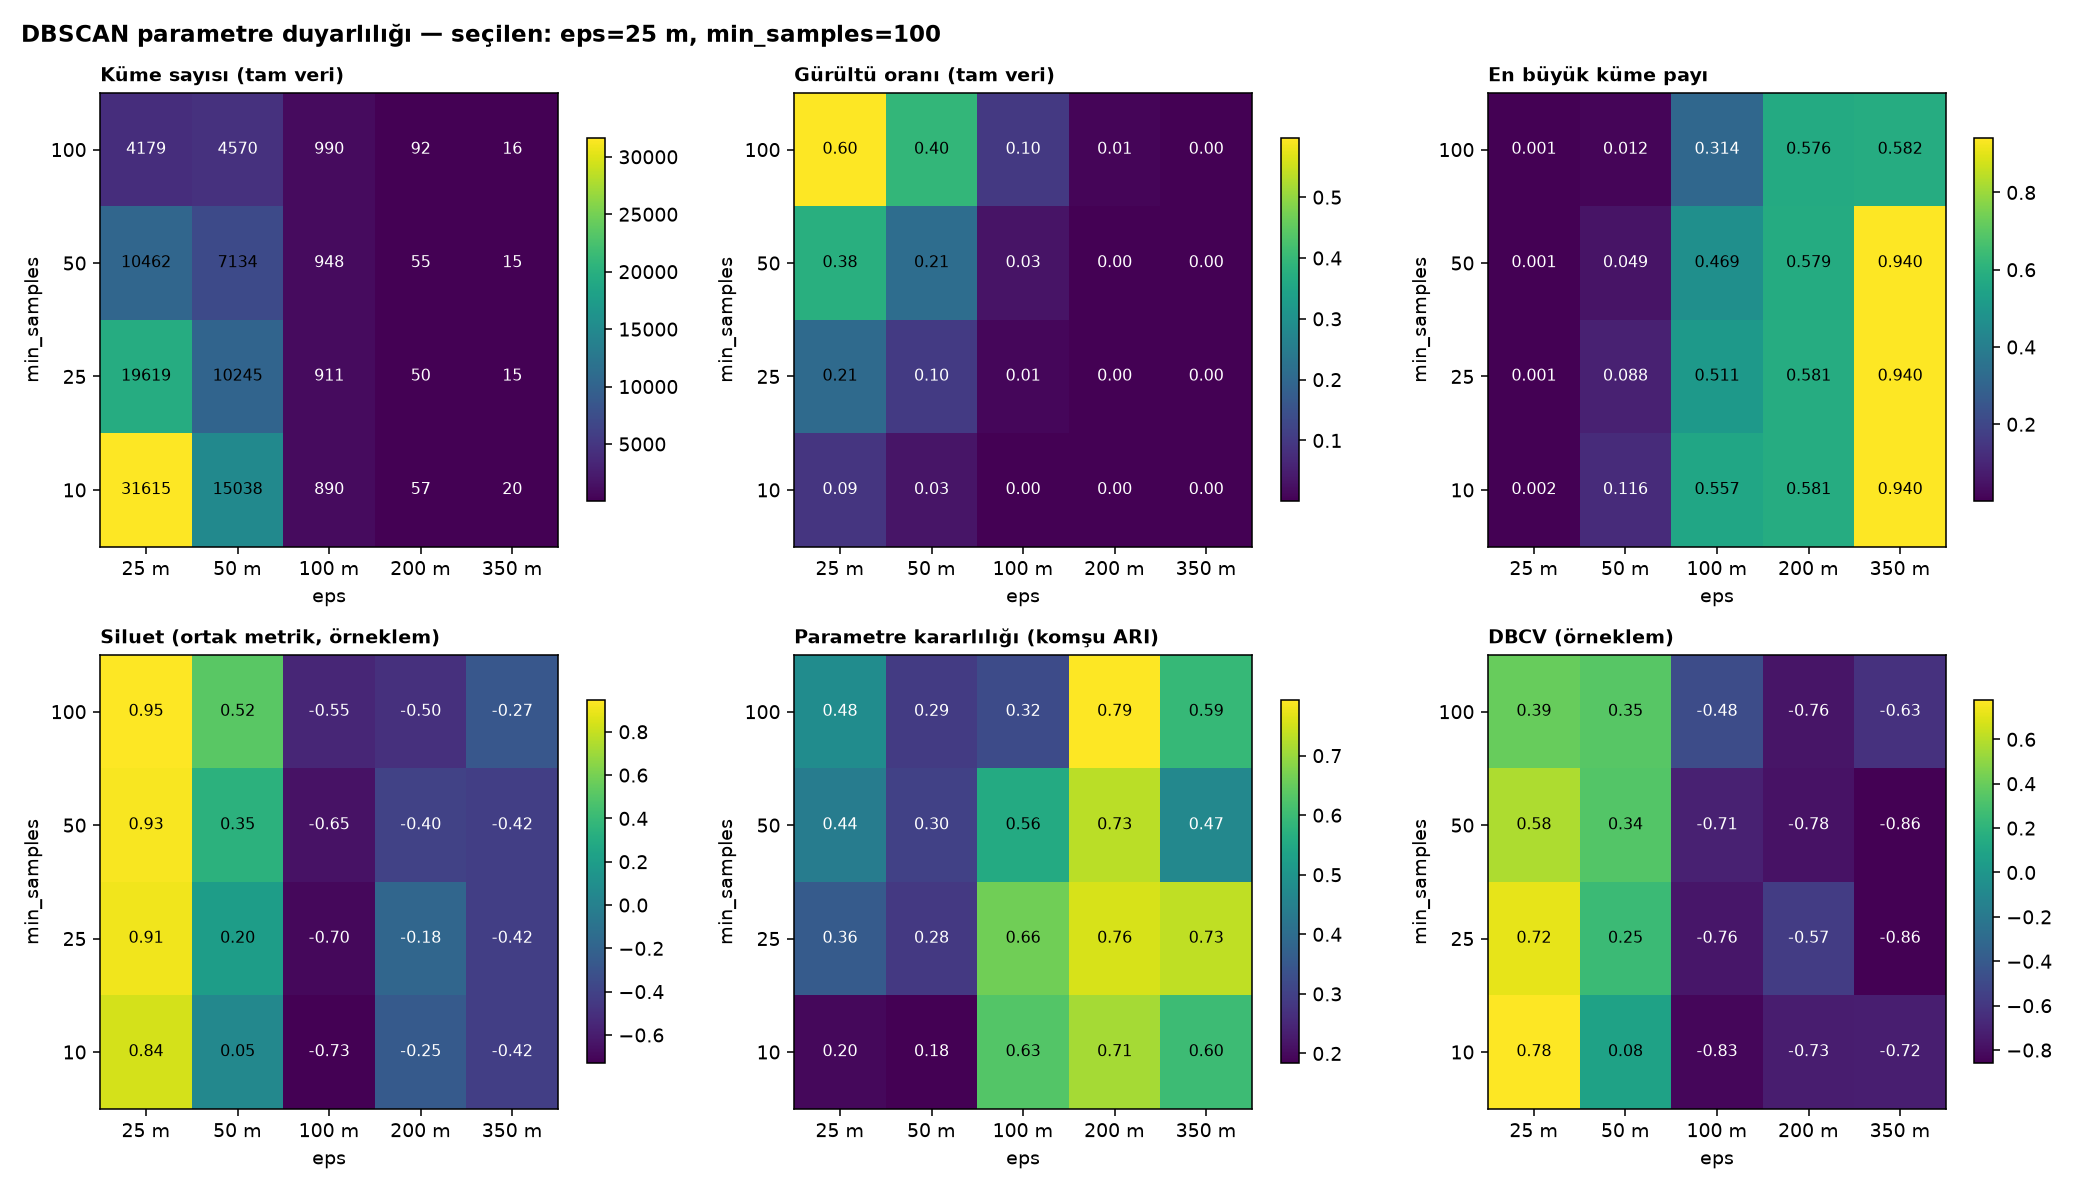

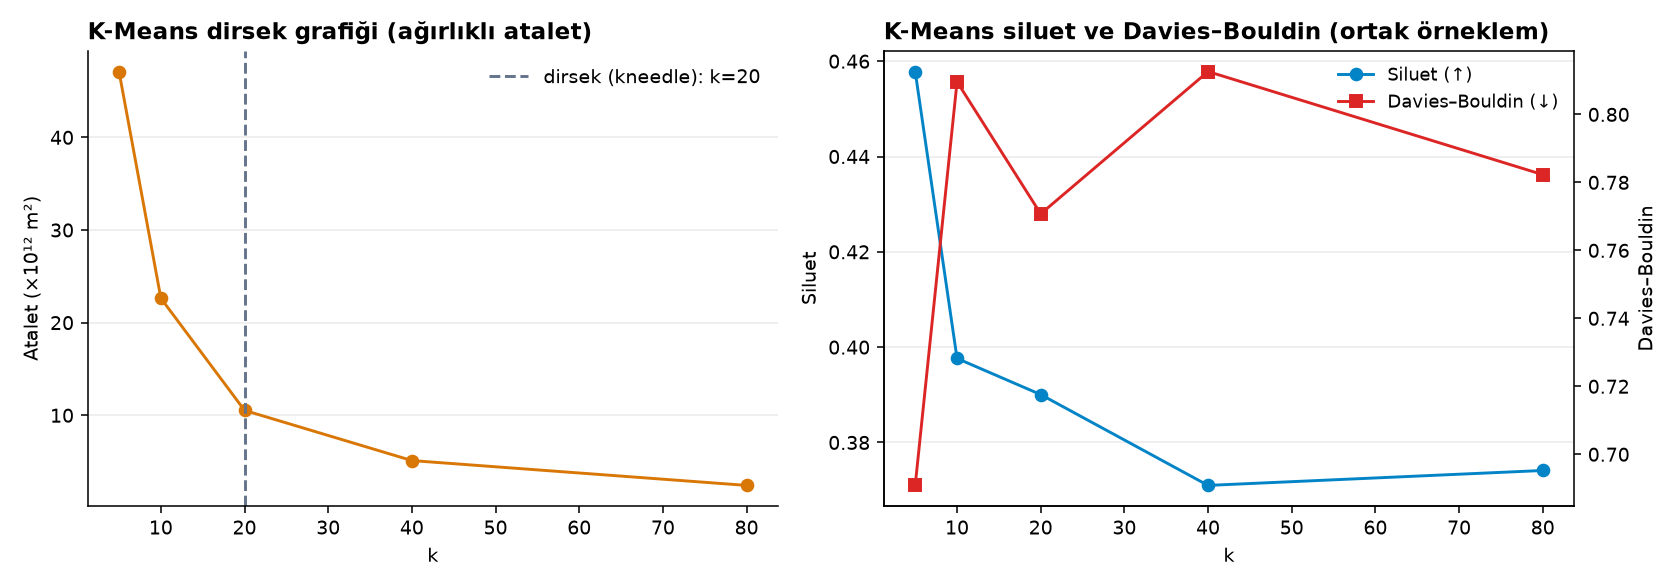

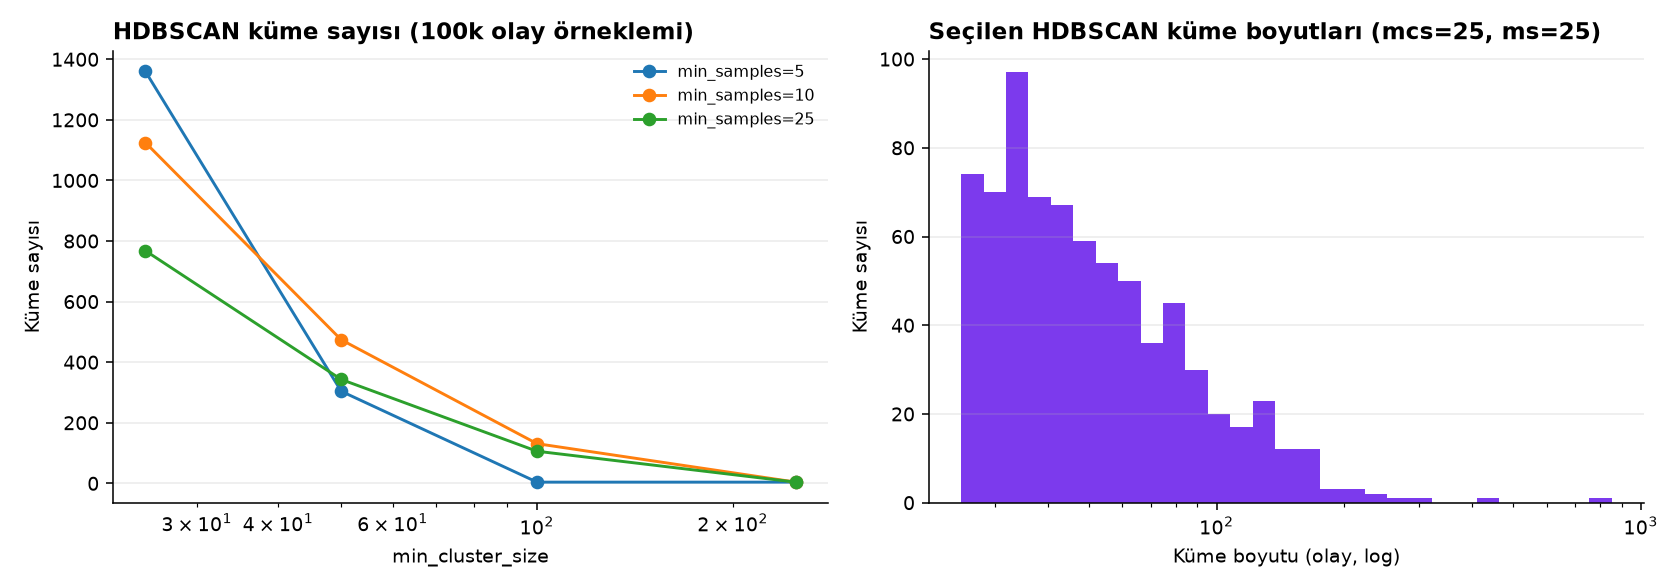

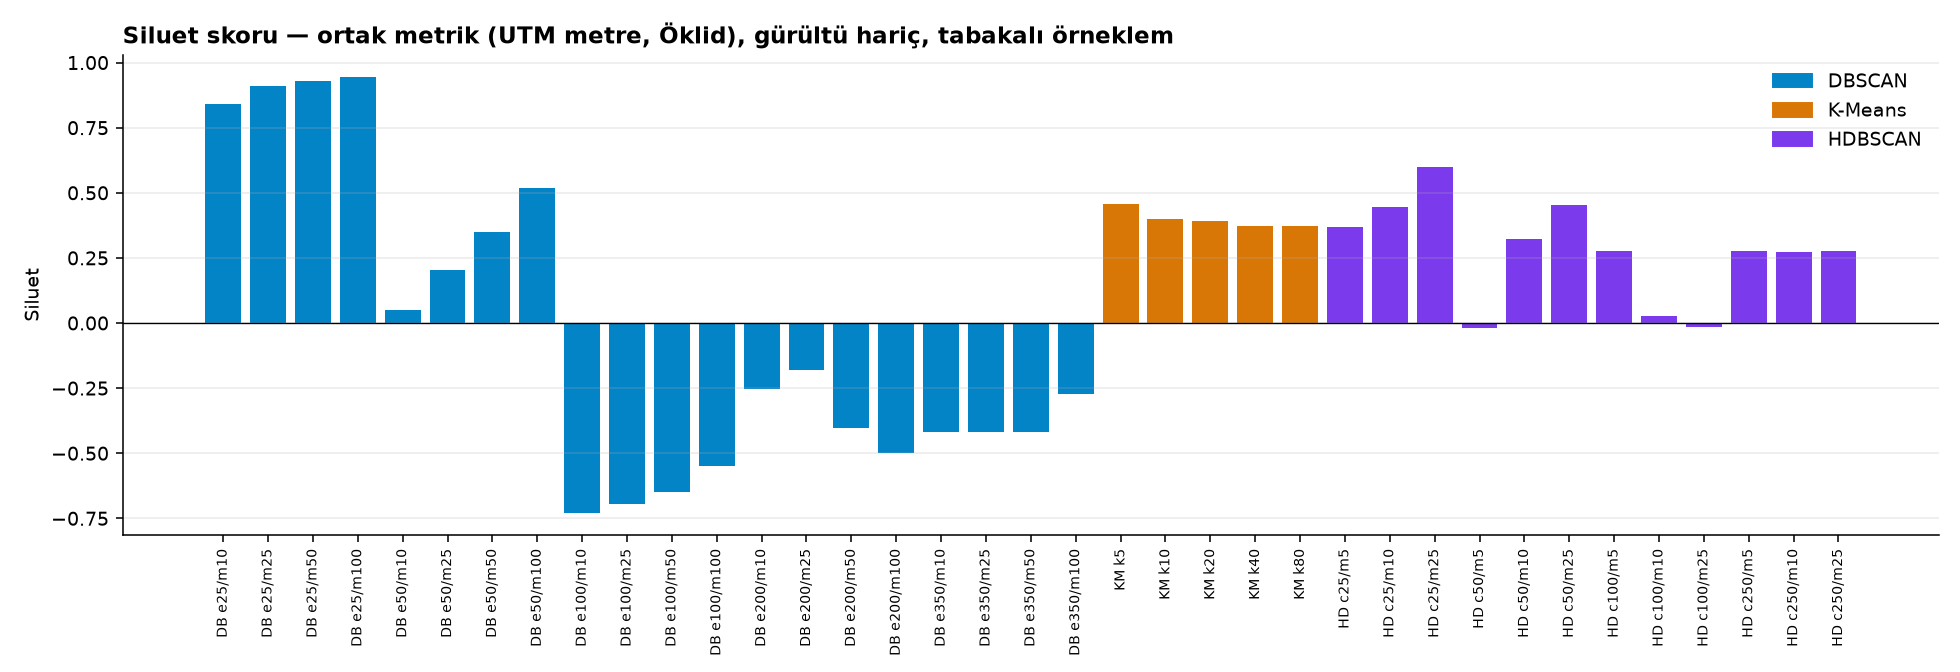

In [8]:
for f in ("dbscan_parameter_sensitivity.png", "kmeans_elbow_silhouette.png", "hdbscan_distribution.png",
          "silhouette_all_configs.png"):
    fig(f)

## 6. Seçim ve kaynak kayıtlarla eşleşme

Seçim ölçütleri sonuçlardan önce tanımlandı (`configs/phase3.toml`, `[selection]`). Aşağıdaki hücre seçilen
modellerin küme sayısı ve gürültü oranını **etiket dosyalarından yeniden sayar** ve `results.json` ile karşılaştırır.

In [9]:
sel = R["selection"]
rows = {r["experiment_id"]: r for r in R["evaluation"]["table"]}
check = []
for alg in ("dbscan", "kmeans", "hdbscan"):
    rec = REG[sel[alg]]
    with np.load(rec["labels_path"]) as z:
        st = cluster_stats(z["labels"])
    rep = rows[sel[alg]].get("full") or rows[sel[alg]]["eval_set"]
    check.append({"algoritma": alg, "deney": sel[alg], "parametreler": rec["params"],
                  "küme (etiket)": st["n_clusters"], "küme (rapor)": rep["n_clusters"],
                  "gürültü (etiket)": round(st["noise_ratio"], 4), "gürültü (rapor)": round(rep["noise_ratio"], 4)})
    assert st["n_clusters"] == rep["n_clusters"] and abs(st["noise_ratio"] - rep["noise_ratio"]) < 1e-9
pd.DataFrame(check)

,algoritma,deney,parametreler,küme (etiket),küme (rapor),gürültü (etiket),gürültü (rapor)
0,dbscan,dbscan-52abd2c018,"{'eps_m': 25, 'min_samples': 100}",4179,4179,0.5969,0.5969
1,kmeans,kmeans-24c07e9946,{'k': 5},5,5,0.0000,0.0000
2,hdbscan,hdbscan-ba3a1ff58d,"{'min_cluster_size': 25, 'min_samples': 25}",768,768,0.5471,0.5471


In [10]:
pd.read_csv(REP / "tables" / "selected_models_comparison.csv").round(3)

,algorithm,experiment_id,fit_scope,features,n_clusters_full,noise_ratio_full,largest_cluster_share_full,eval_set_n_clusters,eval_set_noise_ratio,eval_set_largest_cluster_share,parameter_stability_ari,runtime_s,peak_memory_mb,fit_memory_mb,admissible,parameters,silhouette_common,silhouette_haversine,davies_bouldin,dbcv
0,dbscan,dbscan-52abd2c018,tam veri (ağırlıklı benzersiz konum),A_dbscan_haversine_weighted,4179.0,0.597,0.001,4171,0.596,0.001,0.48,3.870,962.0,138.4,True,"{""eps_m"": 25, ""min_samples"": 100}",0.945,0.945,0.090,0.394
1,kmeans,kmeans-24c07e9946,tam veri (ağırlıklı benzersiz konum),B_kmeans_projected_weighted,5.0,0.000,0.282,5,0.000,0.280,NaN,0.796,965.4,139.4,False,"{""k"": 5}",0.458,NaN,0.691,-0.852
2,hdbscan,hdbscan-ba3a1ff58d,örneklem (100k olay),B_kmeans_projected,NaN,NaN,NaN,768,0.547,0.009,NaN,68.883,965.1,179.8,True,"{""min_cluster_size"": 25, ""min_samples"": 25}",0.601,NaN,0.477,0.260


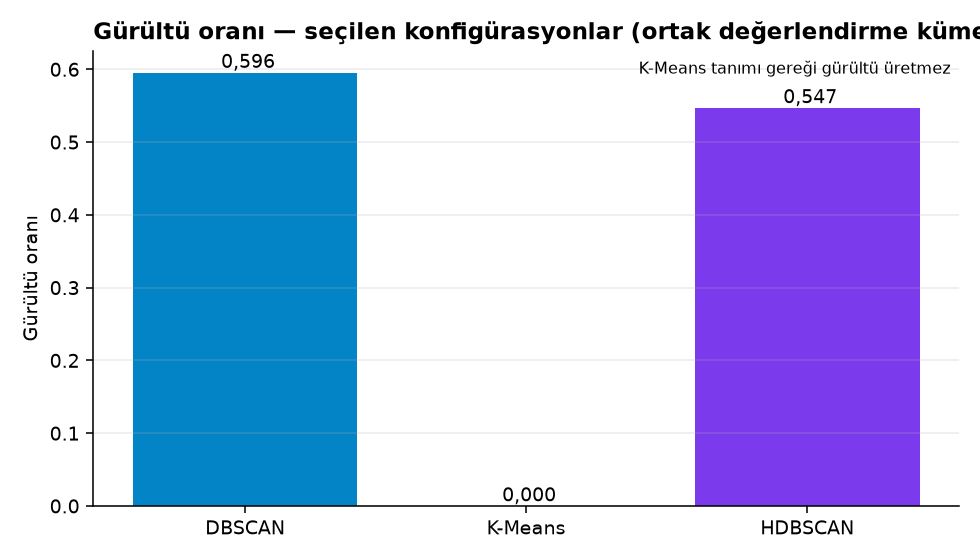

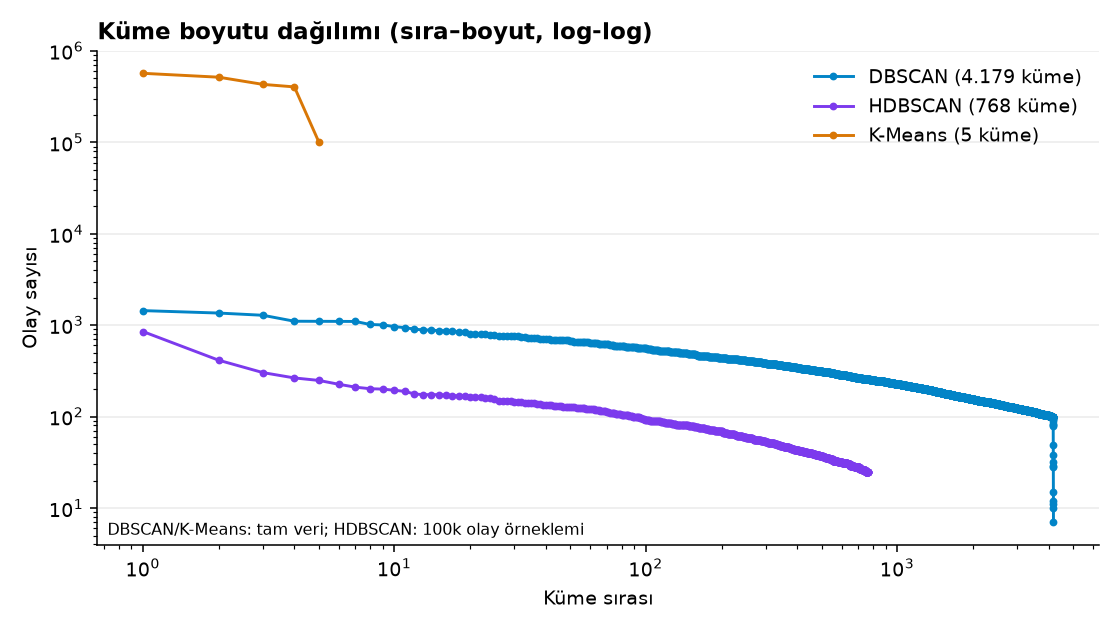

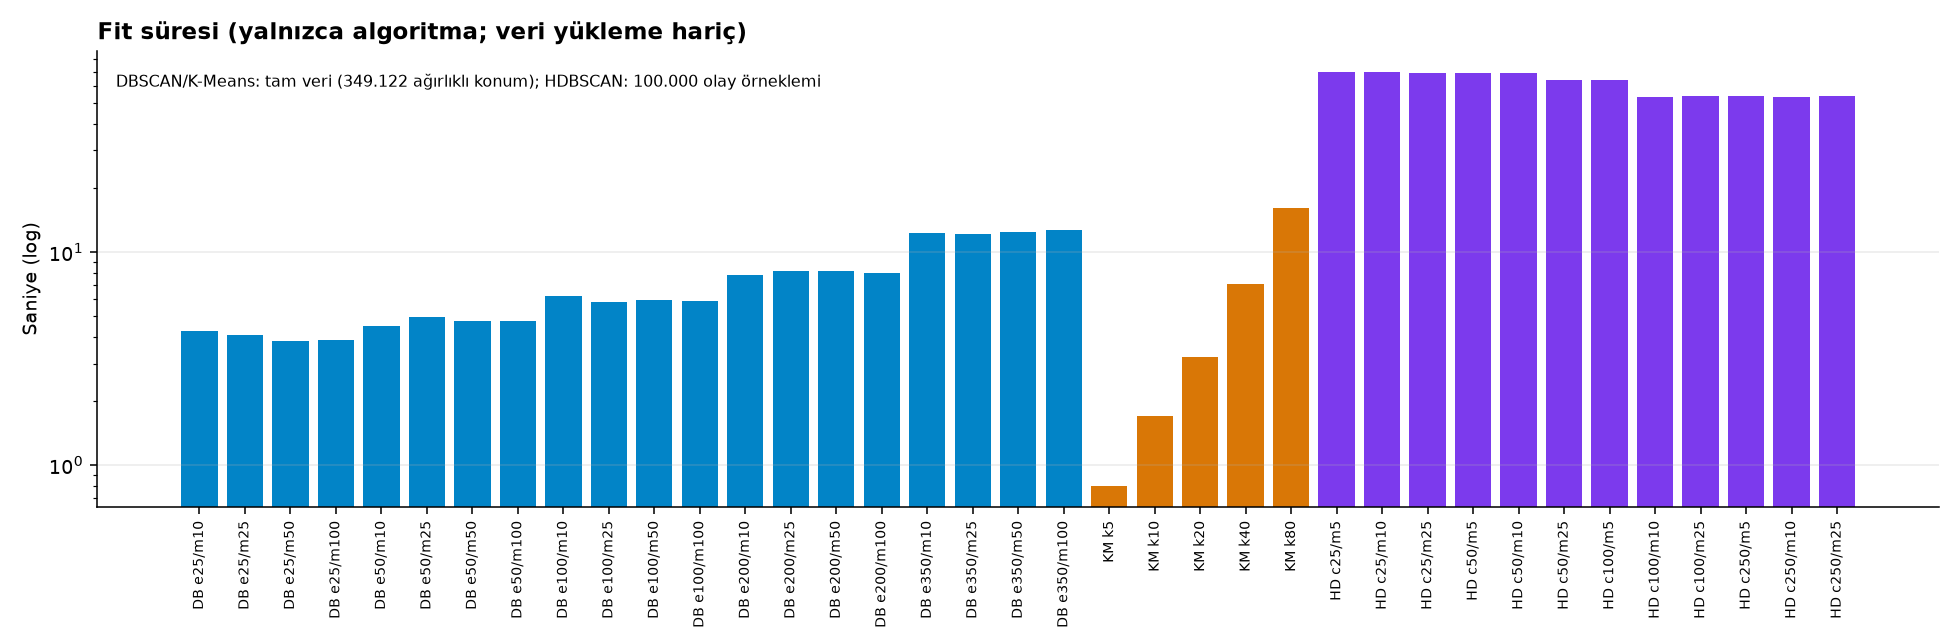

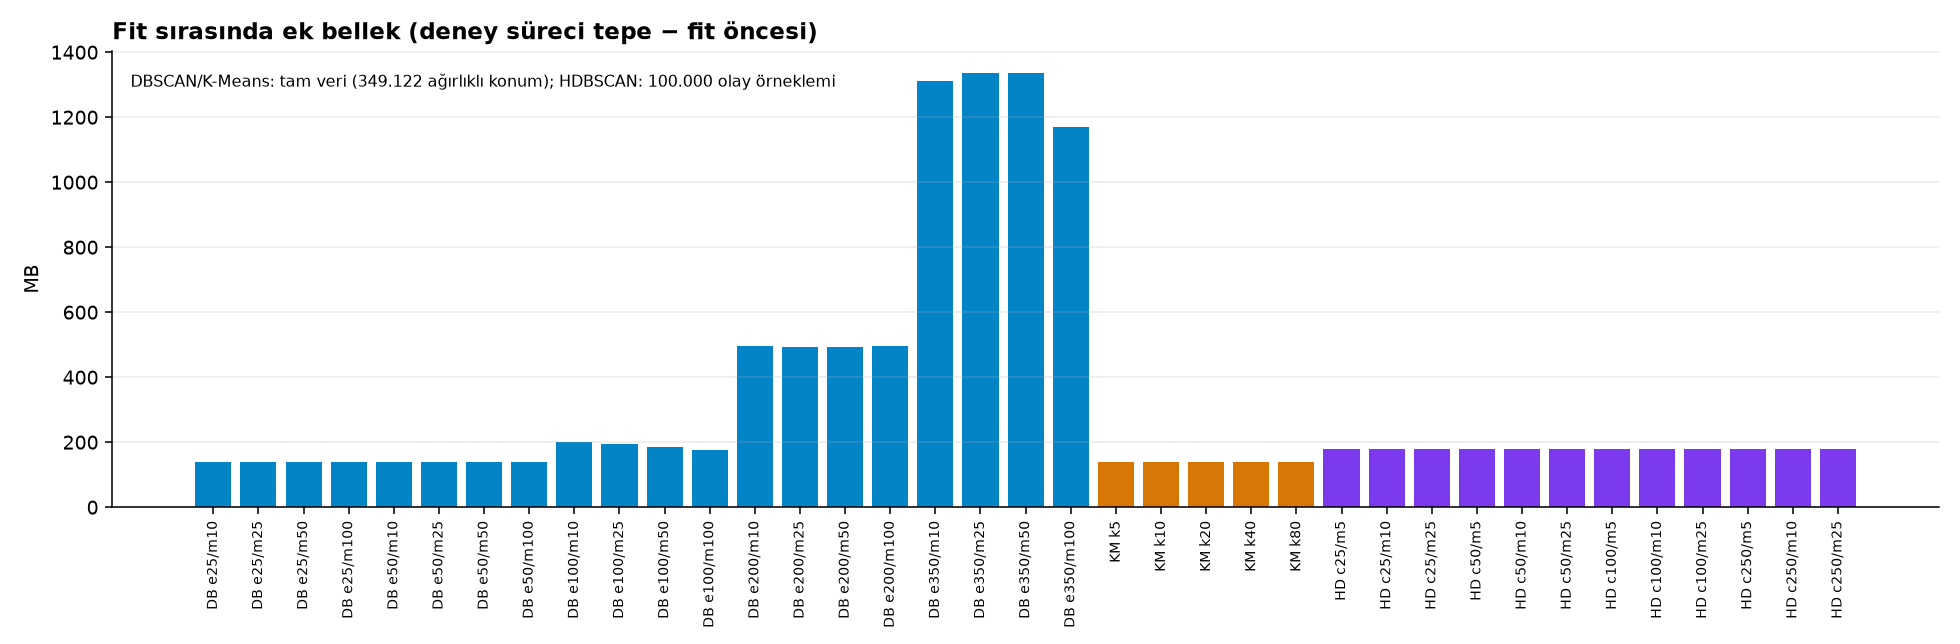

In [11]:
for f in ("noise_ratio_comparison.png", "cluster_size_distribution.png", "runtime_comparison.png", "memory_comparison.png"):
    fig(f)

### 6.1 Seçilen DBSCAN'in (eps=25 m, min_samples=100) gerekçe sınaması

Seçim kuralı (kabul edilebilirlik → komşu ARI → siluet) değiştirilmeden, kabul edilebilir adaylar küme büyüklüğü,
coğrafi ölçek, yoğunluk zincirlenmesi ve yıllar arası süreklilik bakımından karşılaştırılır.

In [12]:
rv = pd.read_csv(REP / "tables" / "dbscan_selection_review.csv")
rv.round(3)

,experiment_id,eps_m,min_samples,selected,noise_ratio_full,parameter_stability_ari,silhouette_common,dbcv,n_clusters,events_per_cluster_median,events_per_cluster_max,unique_locations_median,single_location_cluster_share,extent_diag_median_m,extent_diag_p95_m,extent_diag_max_m,clusters_over_200m_share,events_in_clusters_over_200m_share,active_years_all_share,active_years_10plus_share
0,dbscan-a3d6331c4d,25,10,False,0.093,0.197,0.839,0.776,31615,31.0,4401,5.0,0.013,24.384,92.179,1191.800,0.008,0.082,0.253,0.620
1,dbscan-92b7d618c2,25,25,False,0.205,0.357,0.911,0.718,19619,53.0,2559,6.0,0.007,30.016,83.713,487.955,0.002,0.024,0.425,0.905
2,dbscan-cef8c0d213,25,50,False,0.376,0.440,0.927,0.576,10462,86.0,2062,7.0,0.006,36.662,85.503,314.585,0.000,0.004,0.675,0.971
3,dbscan-52abd2c018,25,100,True,0.597,0.480,0.945,0.394,4179,151.0,1444,8.0,0.007,41.244,87.982,174.422,0.000,0.000,0.850,0.975
4,dbscan-e777e2e1a4,50,50,False,0.213,0.301,0.348,0.337,7134,97.0,98152,12.0,0.003,103.376,399.991,7544.105,0.178,0.586,0.722,0.966
5,dbscan-76502b2d93,50,100,False,0.396,0.290,0.517,0.352,4570,153.0,24748,14.0,0.003,108.765,322.761,4393.614,0.162,0.468,0.861,0.977


In [13]:
s = rv[rv["selected"]].iloc[0]
alt = rv[rv["eps_m"] != s["eps_m"]]
assert s["extent_diag_max_m"] < 200 and s["clusters_over_200m_share"] == 0, "seçilen modelde zincirlenme var"
assert (alt["extent_diag_max_m"] > 1000).all(), "eps=50 adaylarında zincirlenme beklenen ölçekte değil"
display(Markdown(
    f"- Seçilen modelde en geniş küme köşegeni **{s.extent_diag_max_m:.0f} m**; eps=50 m adaylarında "
    f"{', '.join(f'{v:,.0f} m' for v in alt.extent_diag_max_m)} (cadde boyunca zincirlenme).\n"
    f"- Medyan küme **{s.unique_locations_median:.0f} benzersiz konum / {s.extent_diag_median_m:.0f} m** (kavşak ölçeği); "
    f"tek koordinatlı küme payı %{100 * s.single_location_cluster_share:.1f}.\n"
    f"- 13 yılın tamamında etkin küme payı **%{100 * s.active_years_all_share:.1f}**; bedeli gürültü oranı "
    f"%{100 * s.noise_ratio_full:.1f}. Alternatif eps=25/ms=50 daha çok olayı kapsar "
    f"(gürültü %{100 * rv.query('eps_m == 25 and min_samples == 50').noise_ratio_full.iloc[0]:.1f}) ancak ARI ve "
    "süreklilik daha düşüktür."))

- Seçilen modelde en geniş küme köşegeni **174 m**; eps=50 m adaylarında 7,544 m, 4,394 m (cadde boyunca zincirlenme).
- Medyan küme **8 benzersiz konum / 41 m** (kavşak ölçeği); tek koordinatlı küme payı %0.7.
- 13 yılın tamamında etkin küme payı **%85.0**; bedeli gürültü oranı %59.7. Alternatif eps=25/ms=50 daha çok olayı kapsar (gürültü %37.6) ancak ARI ve süreklilik daha düşüktür.

## 7. Zamansal kararlılık

(a) Seçilen parametreler her yıl aynen uygulanır; (c) `min_samples` yıllık hacme ölçeklenir:
`ms_yıl = max(3, round(ms · N_yıl / N_toplam))`; (b) tam veri modelinin kümeleri yıllara göre izlenir.

In [14]:
ty = pd.read_csv(REP / "tables" / "temporal_by_year.csv")
display(ty[["year", "n_events", "dbscan_n_clusters", "dbscan_noise_ratio", "jaccard_vs_prev_year", "scaled_min_samples",
            "scaled_n_clusters", "scaled_noise_ratio", "scaled_jaccard_vs_prev_year", "kmeans_centroid_shift"]].round(3))
# 13 sabit + 13 ölçekli yıllık DBSCAN ve 13 yıllık K-Means deneyinin kayıtla eşleşmesi
for col in ("dbscan_experiment", "scaled_experiment", "kmeans_experiment"):
    assert all(REG[i]["status"] == "success" for i in ty[col]), col
print("Yıllık deneyler:", 3 * len(ty), "— tümü kayıtta başarılı")
ti = temporal_interpretation(R["temporal"])
pd.Series(ti)

,year,n_events,dbscan_n_clusters,dbscan_noise_ratio,jaccard_vs_prev_year,scaled_min_samples,scaled_n_clusters,scaled_noise_ratio,scaled_jaccard_vs_prev_year,kmeans_centroid_shift
0,2013,171941,13,0.991,NaN,9,5445,0.424,NaN,NaN
1,2014,172751,9,0.994,0.600,9,5323,0.435,0.600,69.413
2,2015,182992,12,0.992,0.438,9,5751,0.425,0.597,112.134
3,2016,192150,20,0.984,0.050,10,4112,0.581,0.453,172.600
4,2017,216917,22,0.985,0.118,11,4231,0.579,0.528,143.485
5,2018,216108,21,0.986,0.459,11,4251,0.582,0.568,129.813
6,2019,193820,11,0.993,0.265,10,4247,0.585,0.541,166.208
7,2020,103838,1,0.999,0.059,5,5289,0.546,0.435,599.573
8,2021,100896,0,1.000,0.000,5,5222,0.558,0.416,97.930
9,2022,93080,0,1.000,NaN,5,4619,0.579,0.418,207.955


Yıllık deneyler: 39 — tümü kayıtta başarılı


events_pre_median                                            192150.0
events_post_median                                            91047.0
fixed_clusters_pre_median                                        13.0
fixed_clusters_post_median                                        0.0
fixed_noise_min                                              0.983596
fixed_jaccard_undefined_years                      [2022, 2023, 2024]
fixed_few_cluster_years          [2020, 2021, 2022, 2023, 2024, 2025]
scaled_ms_pre                                             [9, 10, 11]
scaled_ms_post                                                 [4, 5]
scaled_clusters_pre_median                                     4251.0
scaled_clusters_post_median                                    5255.5
scaled_jaccard_pre_median                                    0.554582
scaled_jaccard_post_median                                   0.416303
scaled_noise_pre_median                                      0.579305
scaled_noise_post_me

{'n_clusters': 4179, 'share_active_all_years': 0.8504426896386695, 'share_active_10plus_years': 0.9746350801627184, 'events_in_clusters_active_all_years_share': 0.8798229466584853}


,years,spearman_cluster_counts,top50_overlap
0,2013-2014,0.795,0.78
1,2014-2015,0.790,0.68
2,2015-2016,0.497,0.42
3,2016-2017,0.664,0.40
4,2017-2018,0.743,0.62
5,2018-2019,0.678,0.60
6,2019-2020,0.607,0.52
7,2020-2021,0.625,0.60
8,2021-2022,0.614,0.50
9,2022-2023,0.623,0.62


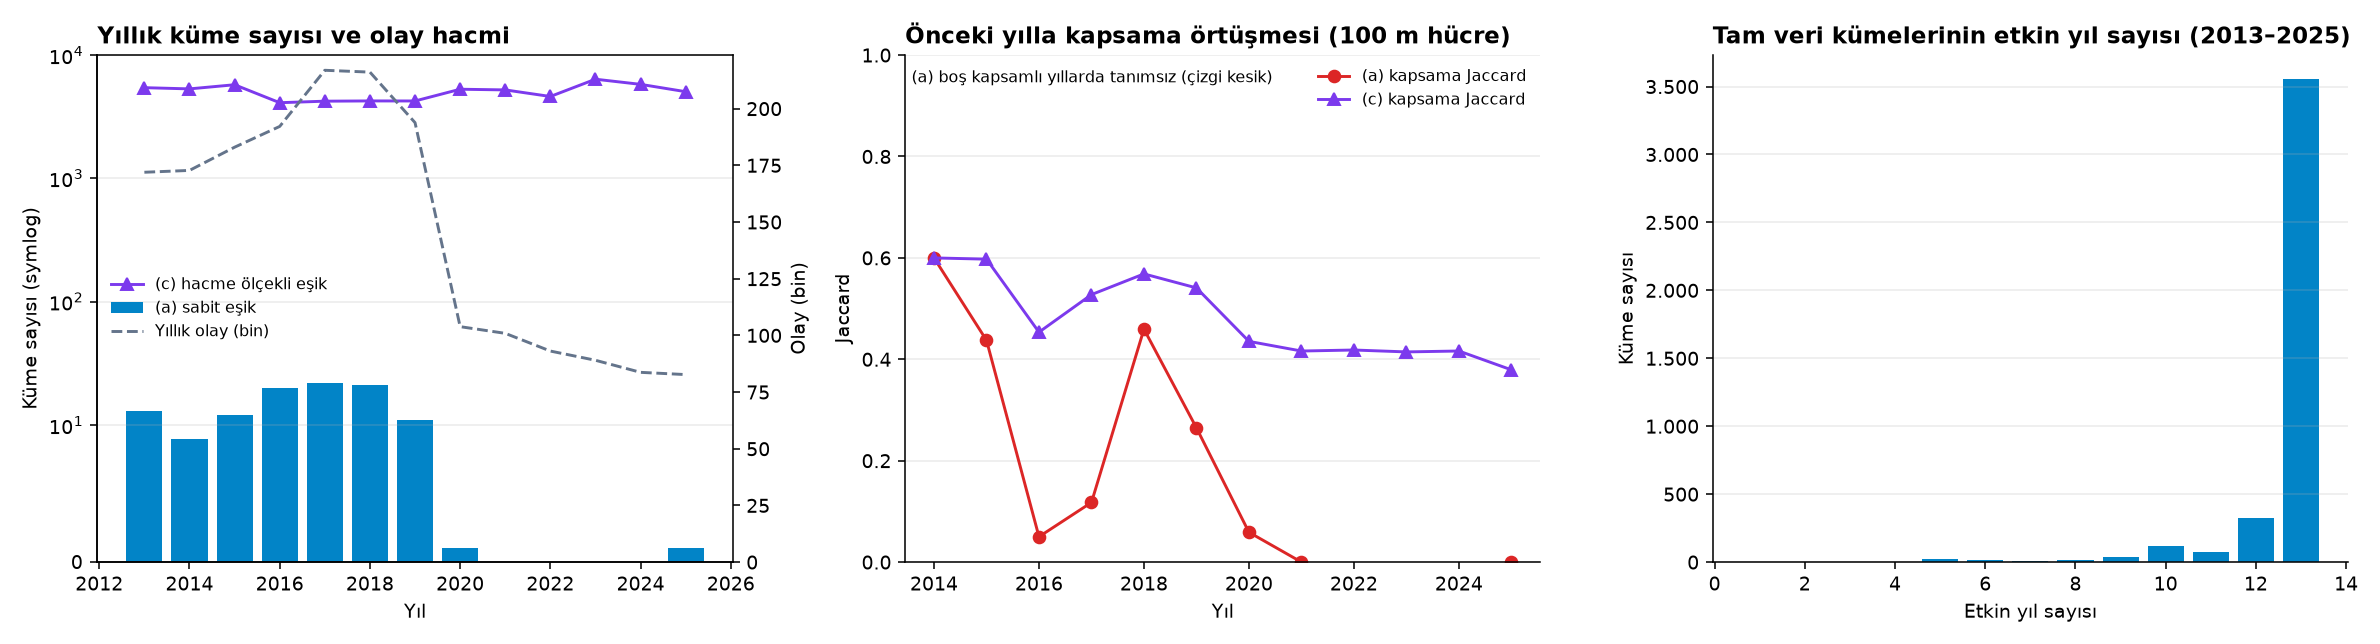

In [15]:
pers = R["temporal"]["persistence"]
print({k: pers[k] for k in ("n_clusters", "share_active_all_years", "share_active_10plus_years",
                            "events_in_clusters_active_all_years_share")})
display(pd.DataFrame(pers["consecutive"]).round(3))
fig("temporal_stability.png")

**Yorum.** Sabit eşikte (a) yıllık küme sayısının 2020 sonrası sıfıra inmesi, kaza hacminin yaklaşık yarıya
düşmesinin sonucudur: tam veri için seçilen `min_samples=100`, tek bir yılın hacmiyle neredeyse hiçbir konumda
sağlanmaz. Bu nedenle (a) bir kararlılık ölçüsü olarak kullanılamaz. Hacme ölçekli (c) yaklaşımında küme sayısı
yıllar boyunca benzer düzeyde kalır ve ardışık yıl Jaccard değeri daha ılımlı düşer; kalan düşüş hacimden
arındırılmış mekânsal değişimi ve düşük eşiğin (ms 4–5) gürültüsünü birlikte içerir. Hacimden bağımsız en
doğrudan ölçü (b) kalıcılıktır.

## 8. Veri kalitesi duyarlılığı

,variant,experiment_id,status,excluded_events,weight_cap,n_clusters,noise_ratio,baseline_n_clusters_on_common,baseline_noise_ratio_on_common,ari_vs_baseline_common_events,noise_status_agreement,baseline_clusters_retained_share,baseline_events_in_retained_clusters_share
0,exclude_geocode_fallback,dbscan-ff11611896,success,1844,NaN,4175,0.5975,4178,0.5974,0.9997,0.9999,0.9990,0.9997
1,exclude_borough_conflict,dbscan-63cefd356e,success,2365,NaN,4173,0.5969,4179,0.5968,0.9996,0.9998,0.9986,0.9996
2,exclude_nearshore,dbscan-3e62e9c871,success,9394,NaN,4152,0.5985,4154,0.5985,1.0000,1.0000,0.9995,1.0000
3,cap_repeated_weights,dbscan-3561817091,success,0,73.0,4059,0.6068,4179,0.5969,0.9741,0.9901,0.9706,0.9762


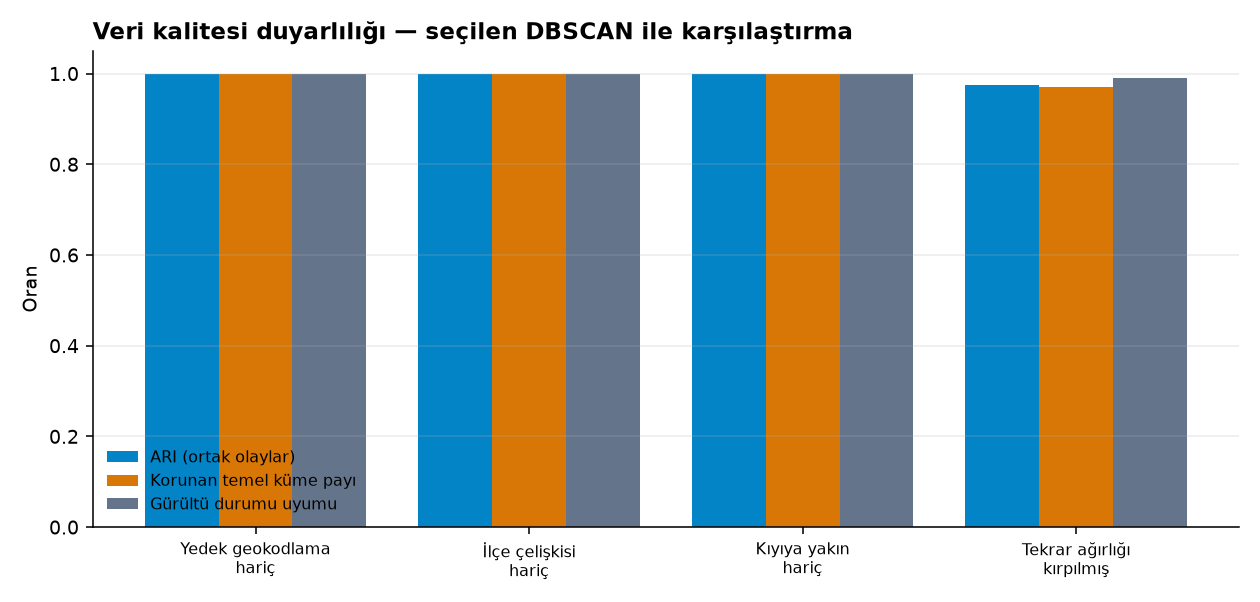

In [16]:
display(pd.read_csv(REP / "tables" / "data_quality_sensitivity.csv").round(4))
fig("data_quality_sensitivity.png")

## 9. Küme profilleri (seçilen DBSCAN)

In [17]:
summ = pd.read_parquet(P3 / "cluster_summary_dbscan.parquet")
pts = pd.read_parquet(P3 / "cluster_points_dbscan.parquet", columns=["cluster_id"])
assert summ["n_events"].sum() == int((pts["cluster_id"] >= 0).sum()), "profil olay sayıları üyeliklerle uyuşmuyor"
assert len(summ) == R["profiles"]["dbscan_counts"]["clusters"]
print(R["profiles"]["dbscan_counts"])
summ.head(15)[["rank_by_events", "n_events", "n_unique_locations", "dominant_borough", "centroid_lat", "centroid_lon",
               "radius_p90_m", "injury_crashes", "fatal_crashes", "peak_hour", "top_streets"]]

{'clusters': 4179, 'events': 814578, 'fatal_crashes': 1324, 'injury_crashes': 207412}


,rank_by_events,n_events,n_unique_locations,dominant_borough,centroid_lat,centroid_lon,radius_p90_m,injury_crashes,fatal_crashes,peak_hour,top_streets
0,1,1444,10,BROOKLYN,40.696033,-73.984530,0.361391,203,1,12,"[{""value"": ""TILLARY STREET"", ""count"": 738, ""sh..."
1,2,1358,17,BRONX,40.820213,-73.890666,32.804394,366,1,16,"[{""value"": ""BRUCKNER BOULEVARD"", ""count"": 534,..."
2,3,1284,9,BRONX,40.861863,-73.912784,3.766833,382,0,16,"[{""value"": ""WEST FORDHAM ROAD"", ""count"": 922, ..."
3,4,1105,26,BROOKLYN,40.678166,-73.897519,13.952459,296,0,16,"[{""value"": ""PENNSYLVANIA AVENUE"", ""count"": 382..."
4,5,1103,9,QUEENS,40.762199,-73.756936,17.799028,239,1,17,"[{""value"": ""NORTHERN BOULEVARD"", ""count"": 389,..."
5,6,1100,12,BROOKLYN,40.691615,-73.999242,14.043026,220,0,0,"[{""value"": ""BROOKLYN QUEENS EXPRESSWAY"", ""coun..."
6,7,1099,16,BROOKLYN,40.675736,-73.896857,0.345541,264,1,16,"[{""value"": ""PENNSYLVANIA AVENUE"", ""count"": 524..."
7,8,1018,14,BROOKLYN,40.658578,-73.890627,0.359185,295,2,14,"[{""value"": ""PENNSYLVANIA AVENUE"", ""count"": 551..."
8,9,1007,29,BRONX,40.804699,-73.912385,37.901156,282,5,16,"[{""value"": ""BRUCKNER BOULEVARD"", ""count"": 456,..."
9,10,965,8,MANHATTAN,40.760601,-73.964325,1.234135,118,1,17,"[{""value"": ""EAST 59 STREET"", ""count"": 552, ""sh..."


In [18]:
pd.DataFrame(R["profiles"]["dbscan_by_borough"])

,dominant_borough,clusters,events
0,BRONX,560,110194
1,BROOKLYN,1150,223567
2,MANHATTAN,1307,259833
3,QUEENS,1009,194308
4,STATEN ISLAND,133,21672


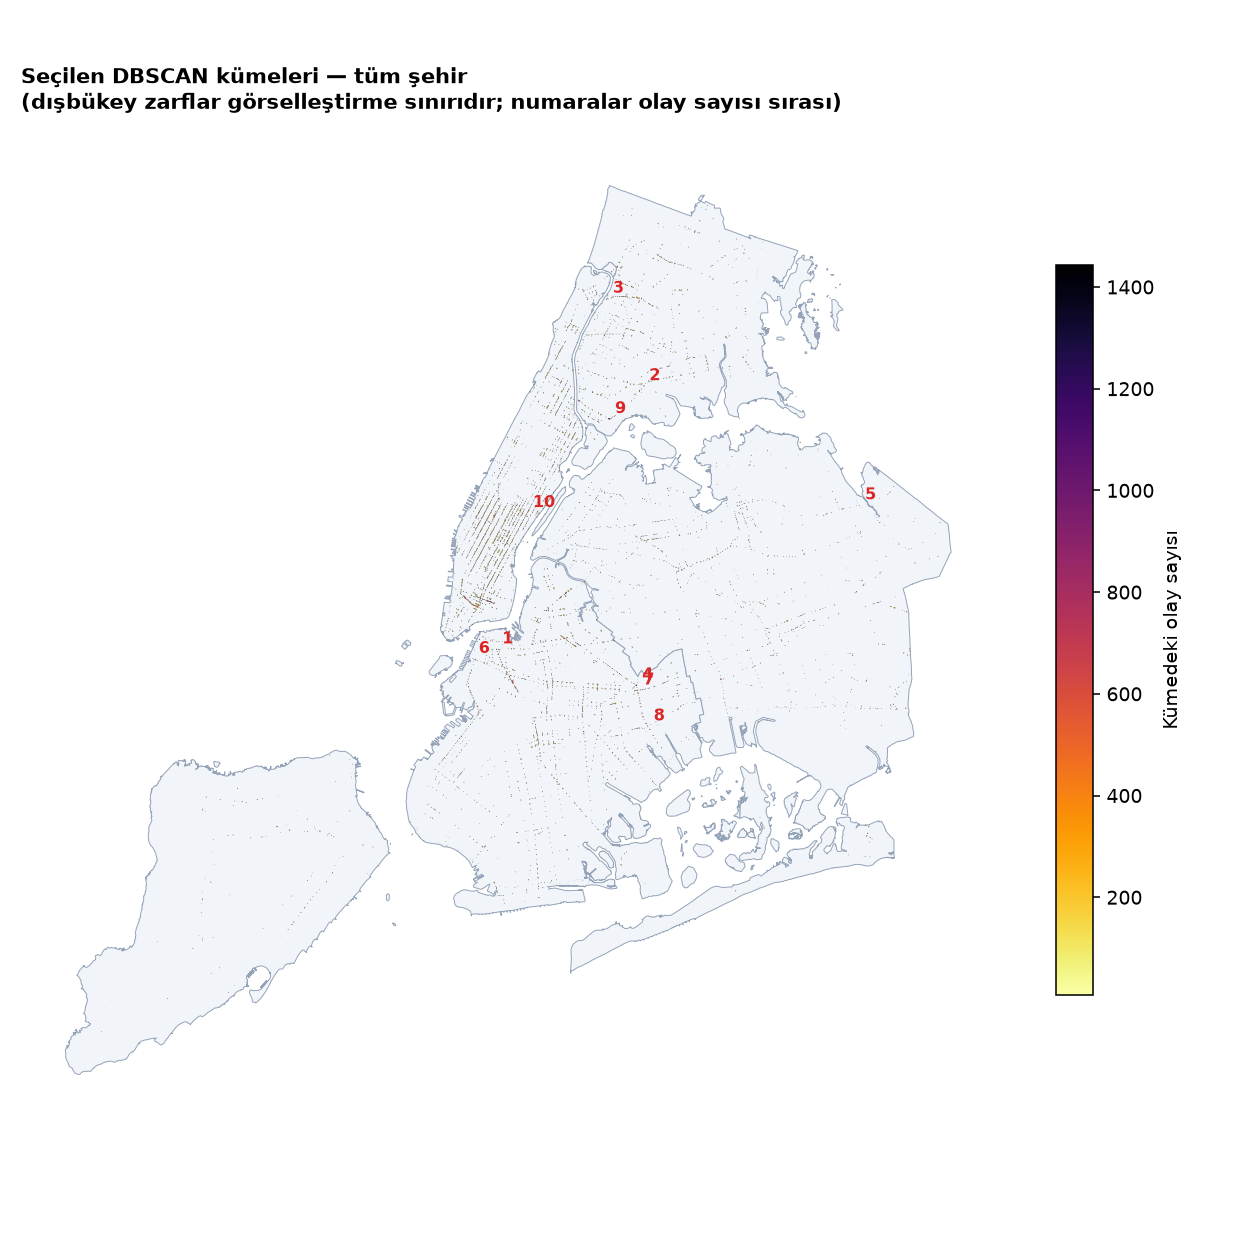

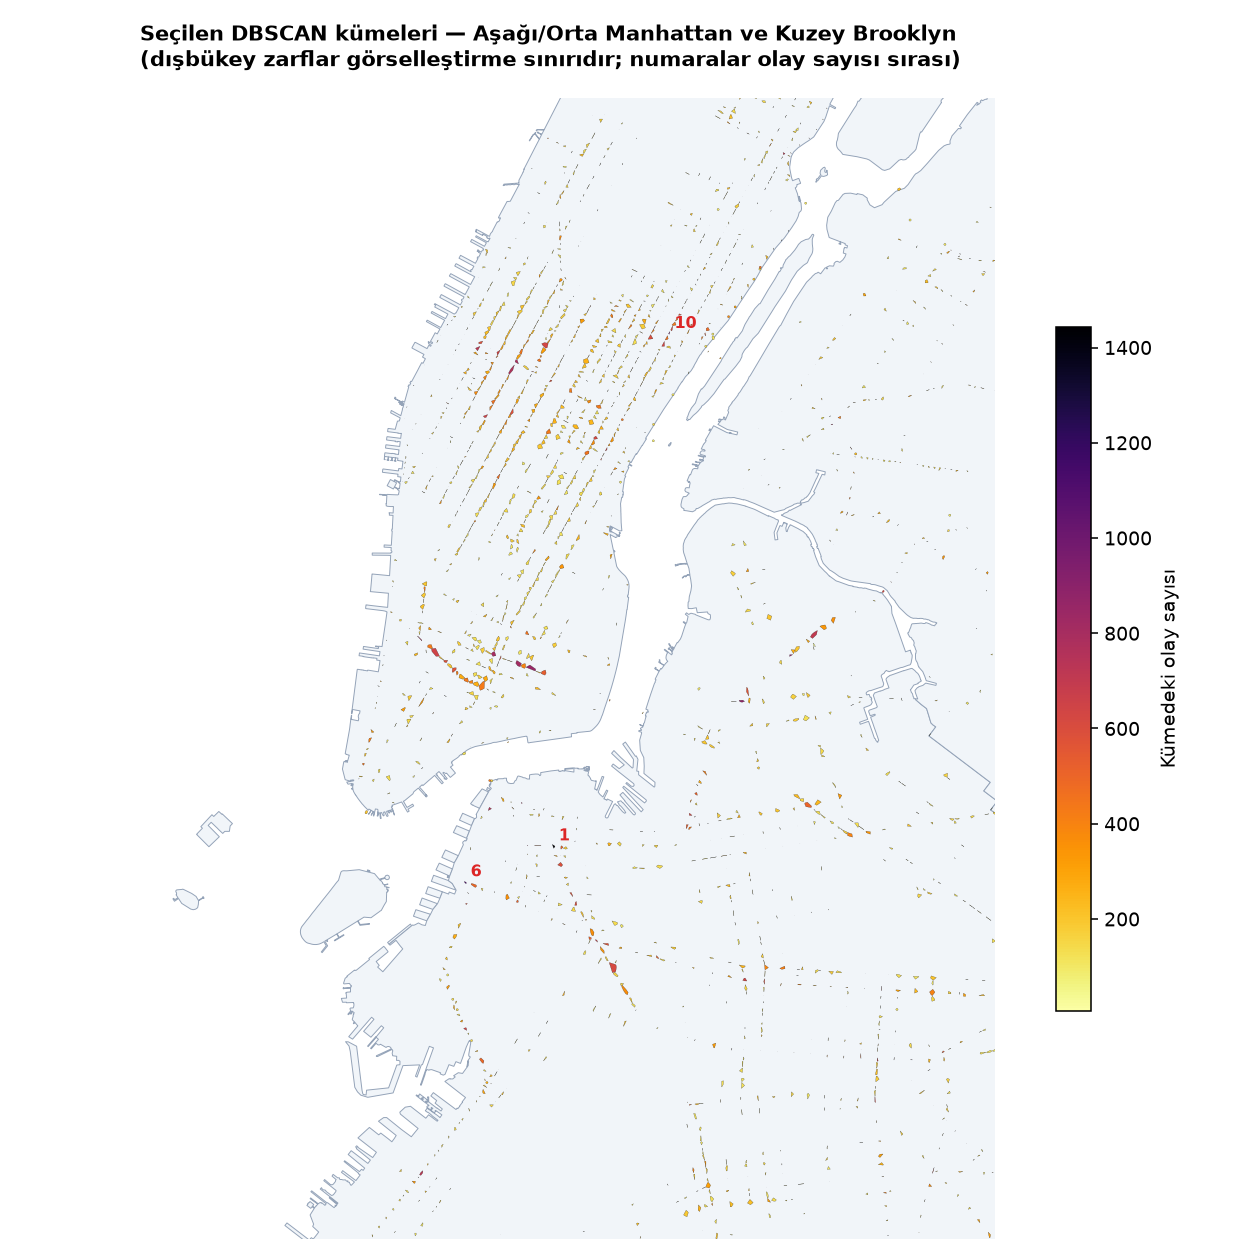

In [19]:
fig("cluster_map_city.png"); fig("cluster_map_manhattan_brooklyn.png")

## 10. Faz 4'e devredilen dosyalar (SHA-256 doğrulaması)

In [20]:
man = json.loads((P3 / "phase4_manifest.json").read_text(encoding="utf-8"))
rows = []
for key, e in man["files"].items():
    p = config.REPO_ROOT / e["path"]
    h = hashlib.sha256(p.read_bytes()).hexdigest()
    assert h == e["sha256"], key
    rows.append({"dosya": e["path"], "satır/öğe": e["rows"], "MB": round(e["bytes"] / 2**20, 2), "sha256": h[:16] + "…"})
pd.DataFrame(rows)

,dosya,satır/öğe,MB,sha256
0,data/processed/h9gi-nx95/snapshot_20261019T155...,2020638.0,11.93,7f8b923db50d0146…
1,data/processed/h9gi-nx95/snapshot_20261019T155...,4179.0,1.14,11319b4ee9e7f151…
2,data/processed/h9gi-nx95/snapshot_20261019T155...,4179.0,2.32,72718479205c09ce…
3,data/processed/h9gi-nx95/snapshot_20261019T155...,2020638.0,10.36,c40ab439f3044661…
4,data/processed/h9gi-nx95/snapshot_20261019T155...,5.0,0.03,66d0e8b805d4d8a2…
5,data/processed/h9gi-nx95/snapshot_20261019T155...,5.0,0.01,ba822ba2585cdfb6…
6,data/processed/h9gi-nx95/snapshot_20261019T155...,NaN,0.16,a8d1d511faa4b0e6…
7,data/processed/h9gi-nx95/snapshot_20261019T155...,NaN,0.01,fe97ae1f58bb9103…
8,data/processed/h9gi-nx95/snapshot_20261019T155...,NaN,0.00,6df2169ae96819cc…


In [21]:
# Tüm rapor şekilleri mevcut ve boş değil
figs = sorted((REP / "figures").glob("*.png"))
assert len(figs) >= 14 and all(f.stat().st_size > 10_000 for f in figs)
[f.name for f in figs]

['cluster_map_city.png',
 'cluster_map_manhattan_brooklyn.png',
 'cluster_size_distribution.png',
 'data_quality_sensitivity.png',
 'dbscan_parameter_sensitivity.png',
 'hdbscan_distribution.png',
 'k_distance.png',
 'kmeans_elbow_silhouette.png',
 'memory_comparison.png',
 'noise_ratio_comparison.png',
 'runtime_comparison.png',
 'silhouette_all_configs.png',
 'temporal_stability.png',
 'weighted_equivalence.png']

## 11. Sınırlılıklar

- HDBSCAN `sample_weight` desteklemediği ve yaklaşık karesel ölçeklendiği için 100k olay örnekleminde çalıştırıldı.
- Tam veri kayıt düzeyi DBSCAN (eps=50, ms=10) komşu çifti sınırını aştığı için çalıştırılmadı; eşdeğerlik dört bölge
  ve 2019 yılı tüm şehir senaryosunda gösterildi.
- Seçilen DBSCAN kronik kavşak yoğunlaşmalarını temsil eder; olayların yaklaşık %60'ı gürültüdür.
- Küme numaraları koşular arasında eşleştirilemez; yıllık karşılaştırma ızgara kapsaması üzerinden yapılır.